In [2]:
import pandas as pd
import numpy as np
import sklearn
import xgboost
import lightgbm 
import torch
import matplotlib.pyplot as plt

In [3]:
import sys
print(sys.executable)

/Users/shayan/Developer/rul-project/.venv/bin/python3.14


In [4]:
print(pd.__version__, np.__version__, sklearn.__version__)

3.0.6 2.5.4 1.9.1


In [5]:
print(xgboost.__version__, lightgbm.__version__, torch.__version__)

3.4.1 4.7.0 2.14.1


In [6]:
print(torch.backends.mps.is_available())

True


In [7]:
cols = ['unit','cycle','op1','op2','op3'] + [f's{i}' for i in range(1,22)]
train = pd.read_csv('../data/train_FD001.txt', sep=r'\s+', header=None, names=cols)
print(train.shape)
train.head()

(20631, 26)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [8]:
train.describe()


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [9]:
pd.set_option('display.max_columns', None)      
sensor_cols = [f's{i}' for i in range(1, 22)]   
setting_cols = ['op1', 'op2', 'op3']            

In [10]:
lifetimes = train.groupby('unit')['cycle'].max()
print("Number of engines:", lifetimes.shape[0])
print(lifetimes.describe())  
print("Rows / engines:", len(train) / lifetimes.shape[0])

Number of engines: 100
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64
Rows / engines: 206.31


In [11]:
stds = train[setting_cols + sensor_cols].std()
stds = stds.sort_values() 
print(stds)

op3    0.000000e+00
s1     0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s10    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64


In [12]:
constant_cols = stds[stds < 1e-6].index.tolist()
print("Constant columns:", constant_cols) 

Constant columns: ['op3', 's1', 's19', 's18', 's10', 's16', 's5']


In [13]:
print(train[setting_cols + sensor_cols].nunique())

op1     158
op2      13
op3       1
s1        1
s2      310
s3     3012
s4     4051
s5        1
s6        2
s7      513
s8       53
s9     6403
s10       1
s11     159
s12     427
s13      56
s14    6078
s15    1918
s16       1
s17      13
s18       1
s19       1
s20     120
s21    4745
dtype: int64


In [14]:
train['max_cycle'] = train.groupby('unit')['cycle'].transform('max')   # each row gets its own engine's lifetime
train['RUL'] = train['max_cycle'] - train['cycle']                     # remaining cycles = lifetime minus current cycle
train = train.drop(columns='max_cycle')                                # remove the helper column

In [15]:
print(train[train['unit'] == 1][['unit', 'cycle', 'RUL']].tail())      # last rows of engine 1

     unit  cycle  RUL
187     1    188    4
188     1    189    3
189     1    190    2
190     1    191    1
191     1    192    0


In [17]:
import os
os.makedirs('../results', exist_ok=True)           # create the results folder if it doesn't exist

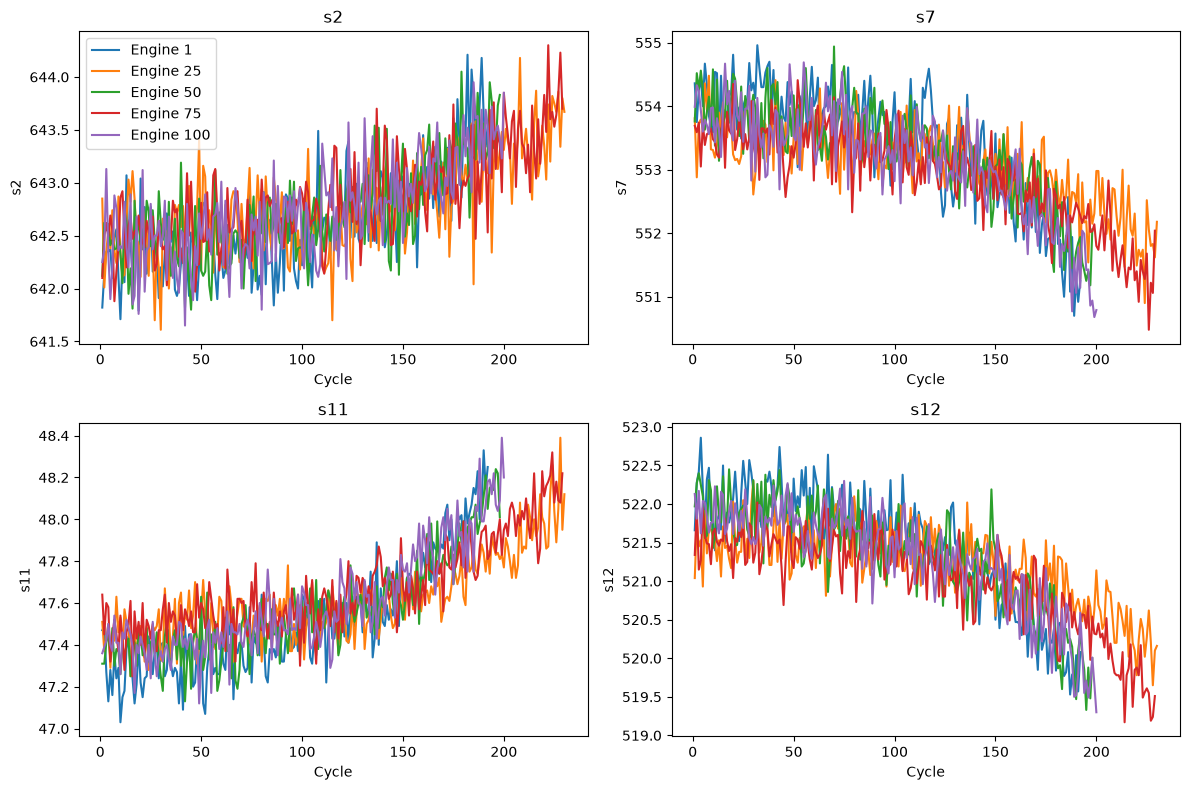

In [18]:
engines = [1, 25, 50, 75, 100]                     # five engines to compare
plot_sensors = ['s2', 's7', 's11', 's12']          # four sensors to try (check they are not in constant_cols)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))    # a 2x2 grid of plots

for ax, sensor in zip(axes.flatten(), plot_sensors):     # loop over each plot square and its sensor
    for e in engines:                                    # loop over the five engines
        d = train[train['unit'] == e]                    # rows belonging to this engine only
        ax.plot(d['cycle'], d[sensor], label=f'Engine {e}')   # sensor value against cycle
    ax.set_title(sensor)                                 # title the plot with the sensor name
    ax.set_xlabel('Cycle')                               # x-axis label
    ax.set_ylabel(sensor)                                # y-axis label

axes[0, 0].legend()                                      # show the engine labels once
plt.tight_layout()                                       # stop the plots overlapping
plt.savefig('../results/sensor_trends.png', dpi=150)     # save the figure for your report
plt.show()                                               # display it in the notebook